# Algoritmos bases de Convolução Linear e Circular

Antes de fazermos a aplicação precisa de construir um algoritmo de convolução linear a partir de uma convolução linear, é importante termos os algoritmos bases para podermos ir usando eles. A reusabilidade de código é uma das maneiras mais consisas de otimização e código limpo que podemos ter.

/home/guilhermemendes/Área de trabalho/Capacitacao_PDS/Relatorio_2/Algoritmo_DFT_e_IDFT.ipynb:115: SyntaxWarning: invalid escape sequence '\p'
  "            real = math.cos(angulo)\n",


=== ESPECTRO DFT INICIAL X[k] (Retangular | Polar) ===
[ 0]    4.000 +   0.000j  |  Mag:   4.000  Fase:     0.0°
[ 1]    0.000 -   2.000j  |  Mag:   2.000  Fase:   -90.0°
[ 2]    0.000 +   0.000j  |  Mag:   0.000  Fase:     0.0°
[ 3]   -0.000 +   2.000j  |  Mag:   2.000  Fase:    90.0°


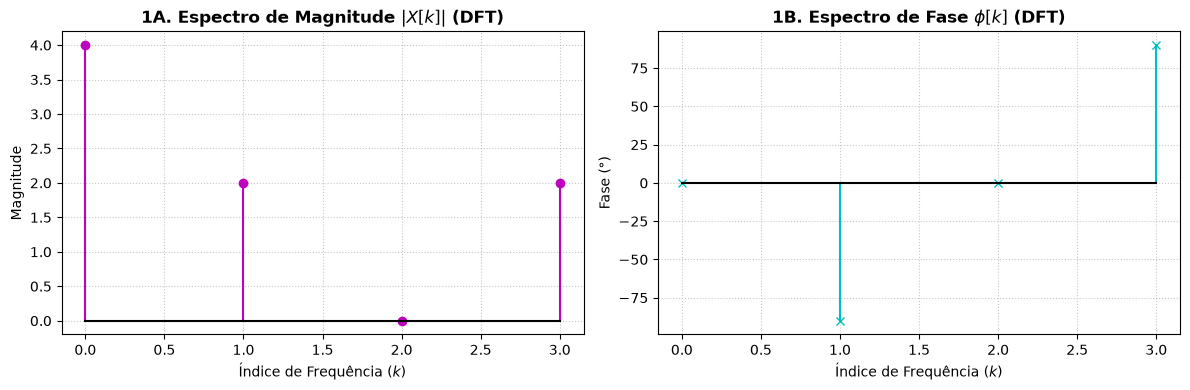

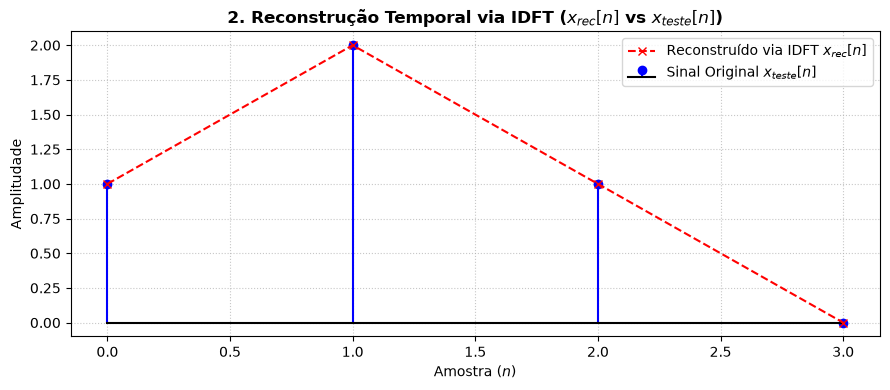

=== VALIDAÇÃO EXPERIMENTAL DAS PROPRIEDADES DA DFT ===
1. Linearidade - Erro Máximo: 3.55e-15
2. Deslocamento Temporal - Erro Máximo: 6.31e-14
3. Deslocamento na Frequência - Erro Máximo: 5.81e-14
4. Reversão Temporal - Erro Máximo: 5.41e-14
5. Conjugação Complexa - Erro Máximo: 5.15e-14
6. Simetria Conjugada (Sinal Real) - Erro Máximo: 5.49e-14
7. Convolução Circular no Tempo - Erro Máximo: 1.38e-13
8. Multiplicação Ponto a Ponto - Erro Máximo: 3.13e-14
9. Teorema de Parseval - Erro Absoluto: 8.88e-15
10. Periodicidade na Frequência - Erro Máximo: 5.32e-14


In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
from ipynb.fs.full.Algoritmo_DFT_e_IDFT import dft_imp, idft_imp

from ipynb.fs.defs.Algoritmo_FFT import fft_radix2

# ==============================================================================
# 0. FUNÇÃO AUXILIAR: IFFT RADIX-2 VIA PROPRIEDADE DA CONJUGAÇÃO
# ==============================================================================

def ifft_radix2(X):
    """Calcula a IFFT utilizando a FFT do conjugado complexo."""
    N = len(X)
    X_conj = np.conj(X)
    x_fft = fft_radix2(X_conj)
    return np.conj(x_fft) / N

def proxima_potencia_de_2(n):
    """Calcula o menor número N_fft >= n que seja potência de 2."""
    return 1 if n == 0 else 2**math.ceil(math.log2(n))


# ==============================================================================
# 1. CONVOLUÇÃO CIRCULAR
# ==============================================================================

def convolucao_circular_dft(x, h):
    """
    Convolução circular de período N = max(len(x), len(h))
    utilizando dft_imp e idft_imp.
    """
    N = max(len(x), len(h))
    
    # Preenchimento para alinhar os tamanhos em N
    x_pad = np.pad(x, (0, N - len(x)))
    h_pad = np.pad(h, (0, N - len(h)))
    
    X = dft_imp(x_pad)
    H = dft_imp(h_pad)
    
    Y = X * H
    return idft_imp(Y).real


def convolucao_circular_fft(x, h):
    """
    Convolução circular via FFT Radix-2.
    Requer que N seja uma potência de 2.
    """
    N = max(len(x), len(h))
    if (N & (N - 1)) != 0:
        N = proxima_potencia_de_2(N)
        
    x_pad = np.pad(x, (0, N - len(x)))
    h_pad = np.pad(h, (0, N - len(h)))
    
    X = fft_radix2(x_pad)
    H = fft_radix2(h_pad)
    
    Y = X * H
    return ifft_radix2(Y).real


# ==============================================================================
# 2. CONVOLUÇÃO LINEAR
# ==============================================================================

def convolucao_linear_dft(x, h):
    """
    Convolução linear via DFT com zero-padding exato para L = N1 + N2 - 1.
    """
    N1, N2 = len(x), len(h)
    L = N1 + N2 - 1  # Tamanho exato sem aliasing temporal
    
    x_pad = np.pad(x, (0, L - N1))
    h_pad = np.pad(h, (0, L - N2))
    
    X = dft_imp(x_pad)
    H = dft_imp(h_pad)
    
    Y = X * H
    return idft_imp(Y).real


def convolucao_linear_fft(x, h):
    """
    Convolução linear via FFT Radix-2.
    Aplica zero-padding até a próxima potência de 2 N_fft >= L e trunca em L.
    """
    N1, N2 = len(x), len(h)
    L = N1 + N2 - 1
    N_fft = proxima_potencia_de_2(L)  # Garante potência de 2 para o Radix-2
    
    x_pad = np.pad(x, (0, N_fft - N1))
    h_pad = np.pad(h, (0, N_fft - N2))
    
    X = fft_radix2(x_pad)
    H = fft_radix2(h_pad)
    
    Y = X * H
    y_full = ifft_radix2(Y).real
    
    return y_full[:L]  # Retorna apenas os L pontos válidos da convolução linear

In [3]:
# --- Sinais de Teste ---
x_sinal = np.array([3, 1, 4, 1, 5, 9, 2, 6], dtype=float)
h_sinal = np.array([1, 2, 1], dtype=float)

# --- Execução dos Algoritmos ---
y_circ_dft = convolucao_circular_dft(x_sinal, h_sinal)
y_circ_fft = convolucao_circular_fft(x_sinal, h_sinal)

y_lin_dft  = convolucao_linear_dft(x_sinal, h_sinal)
y_lin_fft  = convolucao_linear_fft(x_sinal, h_sinal)
y_numpy    = np.convolve(x_sinal, h_sinal)

print("=== CONVOLUÇÃO CIRCULAR ===")
print("Via DFT Arcaica (dft_imp):", np.round(y_circ_dft, 4))
print("Via FFT Radix-2 (fft_radix2):", np.round(y_circ_fft[:len(y_circ_dft)], 4))

print("\n=== CONVOLUÇÃO LINEAR ===")
print("Via DFT Arcaica (dft_imp):", np.round(y_lin_dft, 4))
print("Via FFT Radix-2 (fft_radix2):", np.round(y_lin_fft, 4))
print("Referência NumPy (np.convolve):", np.round(y_numpy, 4))

# Diferença absoluta
erro_lin_dft = np.max(np.abs(y_lin_dft - y_numpy))
erro_lin_fft = np.max(np.abs(y_lin_fft - y_numpy))
print(f"\nErro Máximo DFT vs NumPy: {erro_lin_dft:.2e}")
print(f"Erro Máximo FFT vs NumPy: {erro_lin_fft:.2e}")

=== CONVOLUÇÃO CIRCULAR ===
Via DFT Arcaica (dft_imp): [17. 13.  9. 10. 11. 20. 25. 19.]
Via FFT Radix-2 (fft_radix2): [17. 13.  9. 10. 11. 20. 25. 19.]

=== CONVOLUÇÃO LINEAR ===
Via DFT Arcaica (dft_imp): [ 3.  7.  9. 10. 11. 20. 25. 19. 14.  6.]
Via FFT Radix-2 (fft_radix2): [ 3.  7.  9. 10. 11. 20. 25. 19. 14.  6.]
Referência NumPy (np.convolve): [ 3.  7.  9. 10. 11. 20. 25. 19. 14.  6.]

Erro Máximo DFT vs NumPy: 2.40e-14
Erro Máximo FFT vs NumPy: 1.78e-15


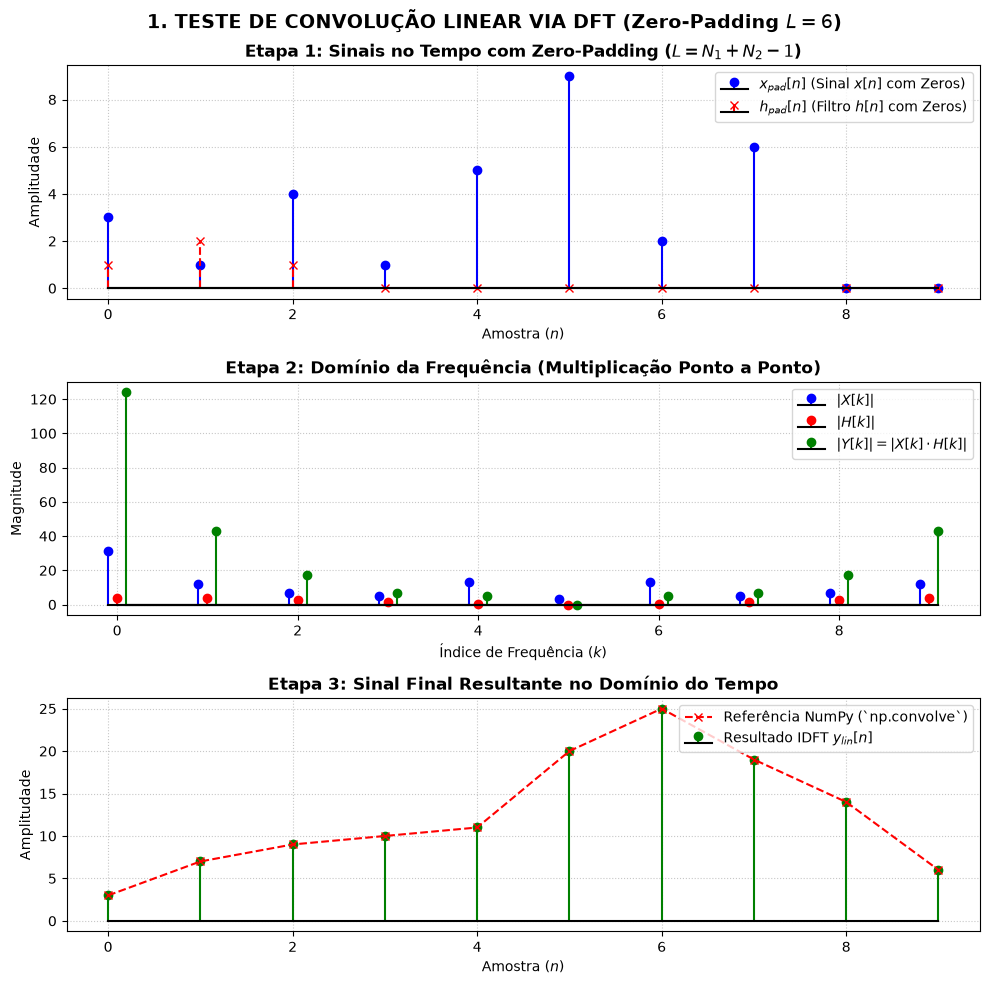

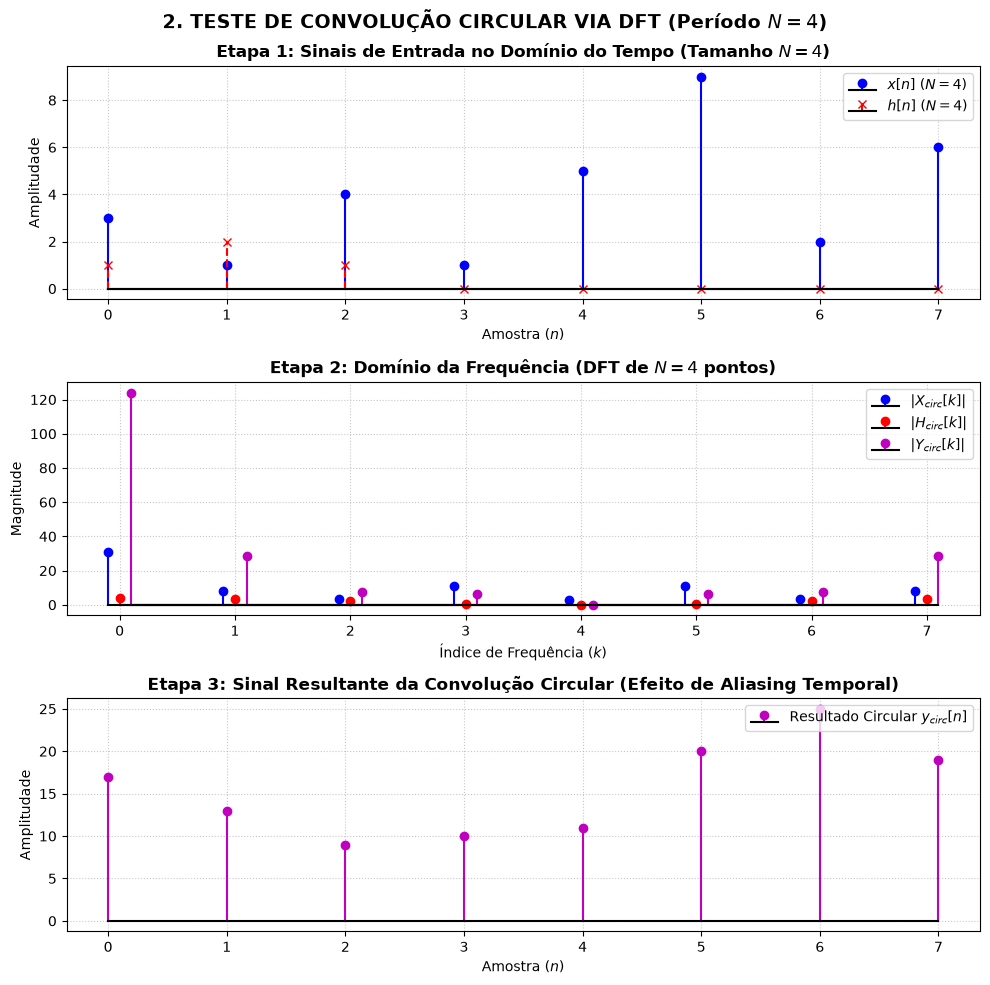

In [4]:
# ==============================================================================
# SINAIS DE ENTRADA PARA OS TESTES
# ==============================================================================
x = np.array([3, 1, 4, 1, 5, 9, 2, 6], dtype=float)
h = np.array([1, 2, 1], dtype=float)

N1, N2 = len(x), len(h)

# ==============================================================================
# TESTE 1: CONVOLUÇÃO LINEAR (VIA DFT COM ZERO-PADDING)
# ==============================================================================
L = N1 + N2 - 1  # Tamanho necessário para evitar aliasing temporal

x_lin_pad = np.pad(x, (0, L - N1))
h_lin_pad = np.pad(h, (0, L - N2))

X_lin = dft_imp(x_lin_pad)
H_lin = dft_imp(h_lin_pad)
Y_lin = X_lin * H_lin
y_lin = idft_imp(Y_lin).real

# --- FIGURA 1: ESTÁGIOS DA CONVOLUÇÃO LINEAR ---
fig1, axs1 = plt.subplots(3, 1, figsize=(10, 10))
fig1.suptitle(r'1. TESTE DE CONVOLUÇÃO LINEAR VIA DFT (Zero-Padding $L=6$)', fontsize=14, fontweight='bold')

# Etapa 1: Sinais Originais com Zero-Padding
eixo_l = np.arange(L)
axs1[0].stem(eixo_l, x_lin_pad, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$x_{pad}[n]$ (Sinal $x[n]$ com Zeros)')
axs1[0].stem(eixo_l, h_lin_pad, linefmt='r--', markerfmt='rx', basefmt='k-', label=r'$h_{pad}[n]$ (Filtro $h[n]$ com Zeros)')
axs1[0].set_title(r'Etapa 1: Sinais no Tempo com Zero-Padding ($L = N_1 + N_2 - 1$)', fontweight='bold')
axs1[0].set_xlabel(r'Amostra ($n$)')
axs1[0].set_ylabel('Amplitudade')
axs1[0].grid(True, ls=':', alpha=0.7)
axs1[0].legend(loc='upper right')

# Etapa 2: Espectro de Frequência e Multiplicação
eixo_k_lin = np.arange(L)
axs1[1].stem(eixo_k_lin - 0.1, np.abs(X_lin), linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$\vert{}X[k]\vert{}$')
axs1[1].stem(eixo_k_lin, np.abs(H_lin), linefmt='r-', markerfmt='ro', basefmt='k-', label=r'$\vert{}H[k]\vert{}$')
axs1[1].stem(eixo_k_lin + 0.1, np.abs(Y_lin), linefmt='g-', markerfmt='go', basefmt='k-', label=r'$\vert{}Y[k]\vert{} = \vert{}X[k] \cdot H[k]\vert{}$')
axs1[1].set_title(r'Etapa 2: Domínio da Frequência (Multiplicação Ponto a Ponto)', fontweight='bold')
axs1[1].set_xlabel(r'Índice de Frequência ($k$)')
axs1[1].set_ylabel('Magnitude')
axs1[1].grid(True, ls=':', alpha=0.7)
axs1[1].legend(loc='upper right')

# Etapa 3: Resultado Temporal Final
y_numpy_ref = np.convolve(x, h)
axs1[2].stem(eixo_l, y_lin, linefmt='g-', markerfmt='go', basefmt='k-', label=r'Resultado IDFT $y_{lin}[n]$')
axs1[2].plot(eixo_l, y_numpy_ref, 'r--x', label=r'Referência NumPy (`np.convolve`)', linewidth=1.5)
axs1[2].set_title(r'Etapa 3: Sinal Final Resultante no Domínio do Tempo', fontweight='bold')
axs1[2].set_xlabel(r'Amostra ($n$)')
axs1[2].set_ylabel('Amplitudade')
axs1[2].grid(True, ls=':', alpha=0.7)
axs1[2].legend(loc='upper right')

plt.tight_layout()
plt.show()


# ==============================================================================
# TESTE 2: CONVOLUÇÃO CIRCULAR (VIA DFT SEM ZERO-PADDING SUFICIENTE)
# ==============================================================================
N_circ = max(N1, N2)  # Período N = 4

x_circ_pad = np.pad(x, (0, N_circ - N1))
h_circ_pad = np.pad(h, (0, N_circ - N2))

X_circ = dft_imp(x_circ_pad)
H_circ = dft_imp(h_circ_pad)
Y_circ = X_circ * H_circ
y_circ = idft_imp(Y_circ).real

# --- FIGURA 2: ESTÁGIOS DA CONVOLUÇÃO CIRCULAR ---
fig2, axs2 = plt.subplots(3, 1, figsize=(10, 10))
fig2.suptitle(r'2. TESTE DE CONVOLUÇÃO CIRCULAR VIA DFT (Período $N=4$)', fontsize=14, fontweight='bold')

# Etapa 1: Sinais Originais com Período N
eixo_n_circ = np.arange(N_circ)
axs2[0].stem(eixo_n_circ, x_circ_pad, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$x[n]$ ($N=4$)')
axs2[0].stem(eixo_n_circ, h_circ_pad, linefmt='r--', markerfmt='rx', basefmt='k-', label=r'$h[n]$ ($N=4$)')
axs2[0].set_title(r'Etapa 1: Sinais de Entrada no Domínio do Tempo (Tamanho $N=4$)', fontweight='bold')
axs2[0].set_xlabel(r'Amostra ($n$)')
axs2[0].set_ylabel('Amplitudade')
axs2[0].grid(True, ls=':', alpha=0.7)
axs2[0].legend(loc='upper right')

# Etapa 2: Espectro de Frequência Circular
axs2[1].stem(eixo_n_circ - 0.1, np.abs(X_circ), linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$\vert{}X_{circ}[k]\vert{}$')
axs2[1].stem(eixo_n_circ, np.abs(H_circ), linefmt='r-', markerfmt='ro', basefmt='k-', label=r'$\vert{}H_{circ}[k]\vert{}$')
axs2[1].stem(eixo_n_circ + 0.1, np.abs(Y_circ), linefmt='m-', markerfmt='mo', basefmt='k-', label=r'$\vert{}Y_{circ}[k]\vert{}$')
axs2[1].set_title(r'Etapa 2: Domínio da Frequência (DFT de $N=4$ pontos)', fontweight='bold')
axs2[1].set_xlabel(r'Índice de Frequência ($k$)')
axs2[1].set_ylabel('Magnitude')
axs2[1].grid(True, ls=':', alpha=0.7)
axs2[1].legend(loc='upper right')

# Etapa 3: Sinal Final Resultante (Com Aliasing Temporal)
axs2[2].stem(eixo_n_circ, y_circ, linefmt='m-', markerfmt='mo', basefmt='k-', label=r'Resultado Circular $y_{circ}[n]$')
axs2[2].set_title(r'Etapa 3: Sinal Resultante da Convolução Circular (Efeito de Aliasing Temporal)', fontweight='bold')
axs2[2].set_xlabel(r'Amostra ($n$)')
axs2[2].set_ylabel('Amplitudade')
axs2[2].grid(True, ls=':', alpha=0.7)
axs2[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

# Script 1: GIF da Convolução Linear via DFT (com Zero-Padding $L = 6$)
Este script anima o cálculo da Convolução Linear: revela o espectro de frequências $X[k]$, $H[k]$ e $Y[k]$ amostra por amostra ($k = 0 \dots L-1$) e, em seguida, reconstrói o sinal de saída no domínio do tempo via IDFT.

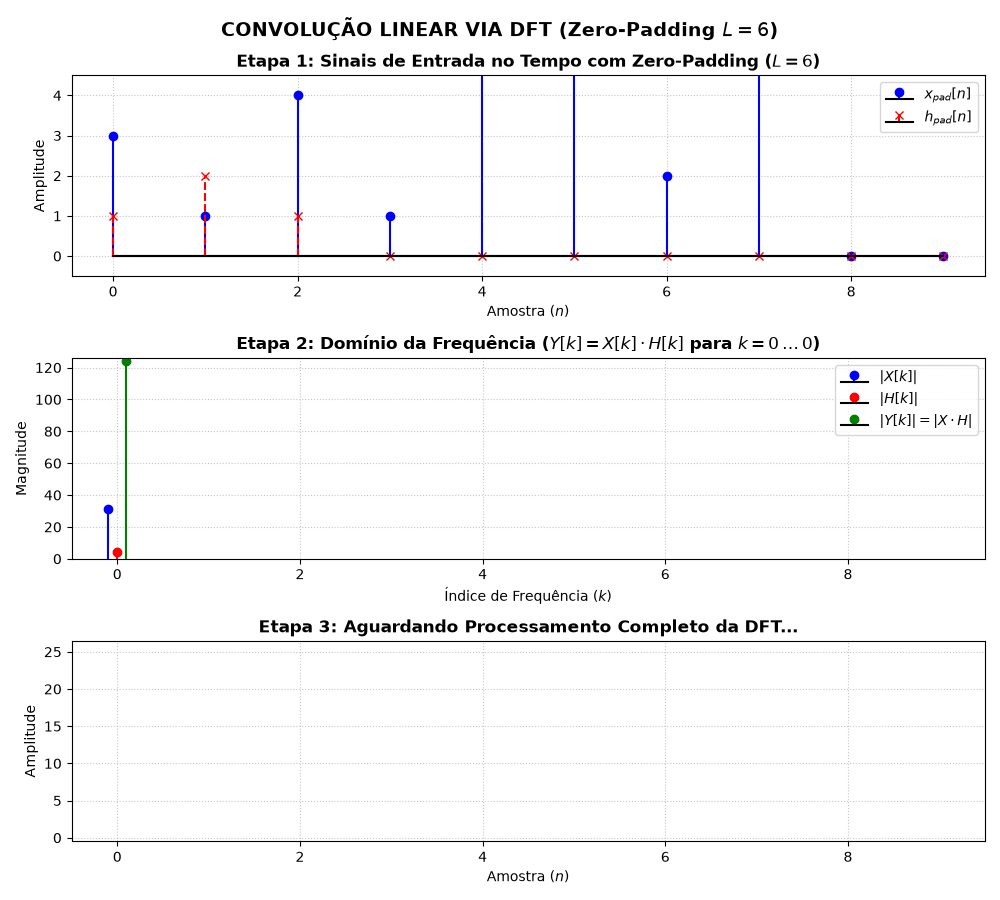

In [5]:
import matplotlib.animation as animation
from IPython.display import Image, display

# Importação dos seus módulos customizados
from ipynb.fs.full.Algoritmo_DFT_e_IDFT import dft_imp, idft_imp

# ==============================================================================
# SINAIS DE TESTE
# ==============================================================================
x = np.array([3, 1, 4, 1, 5, 9, 2, 6], dtype=float)
h = np.array([1, 2, 1], dtype=float)

N1, N2 = len(x), len(h)
L = N1 + N2 - 1  # L = 6 (Zero-padding exato)

x_lin_pad = np.pad(x, (0, L - N1))
h_lin_pad = np.pad(h, (0, L - N2))

X_lin = dft_imp(x_lin_pad)
H_lin = dft_imp(h_lin_pad)
Y_lin = X_lin * H_lin
y_lin = idft_imp(Y_lin).real

# ==============================================================================
# ANIMAÇÃO: 3 ETAPAS DA CONVOLUÇÃO LINEAR
# ==============================================================================
fig1, axs1 = plt.subplots(3, 1, figsize=(10, 9))
eixo_l = np.arange(L)

def draw_frame_linear(frame):
    for ax in axs1:
        ax.clear()
        ax.grid(True, ls=':', alpha=0.7)
        
    # --- Etapa 1: Tempo com Zero-Padding ---
    axs1[0].stem(eixo_l, x_lin_pad, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$x_{pad}[n]$')
    axs1[0].stem(eixo_l, h_lin_pad, linefmt='r--', markerfmt='rx', basefmt='k-', label=r'$h_{pad}[n]$')
    axs1[0].set_title(r'Etapa 1: Sinais de Entrada no Tempo com Zero-Padding ($L = 6$)', fontweight='bold')
    axs1[0].set_xlabel(r'Amostra ($n$)')
    axs1[0].set_ylabel('Amplitude')
    axs1[0].legend(loc='upper right')
    axs1[0].set_ylim(-0.5, 4.5)
    
    # --- Etapa 2: Frequência (Cálculo Ponto a Ponto) ---
    k_count = min(frame + 1, L)
    axs1[1].stem(eixo_l[:k_count] - 0.1, np.abs(X_lin)[:k_count], linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$|X[k]|$')
    axs1[1].stem(eixo_l[:k_count], np.abs(H_lin)[:k_count], linefmt='r-', markerfmt='ro', basefmt='k-', label=r'$|H[k]|$')
    axs1[1].stem(eixo_l[:k_count] + 0.1, np.abs(Y_lin)[:k_count], linefmt='g-', markerfmt='go', basefmt='k-', label=r'$|Y[k]| = |X \cdot H|$')
    axs1[1].set_title(r'Etapa 2: Domínio da Frequência ($Y[k] = X[k] \cdot H[k]$ para $k = 0 \dots %d$)' % (k_count - 1), fontweight='bold')
    axs1[1].set_xlabel(r'Índice de Frequência ($k$)')
    axs1[1].set_ylabel('Magnitude')
    axs1[1].set_xlim(-0.5, L - 0.5)
    axs1[1].set_ylim(0, max(np.abs(Y_lin)) + 2)
    axs1[1].legend(loc='upper right')
    
    # --- Etapa 3: Reconstrução Temporal via IDFT ---
    if frame >= L - 1:
        n_count = frame - (L - 1) + 1
        axs1[2].stem(eixo_l[:n_count], y_lin[:n_count], linefmt='g-', markerfmt='go', basefmt='k-', label=r'IDFT $y_{lin}[n]$')
        axs1[2].plot(eixo_l, np.convolve(x, h), 'r--x', alpha=0.4, label=r'Referência NumPy')
        axs1[2].set_title(r'Etapa 3: Reconstrução Temporal via IDFT ($n = 0 \dots %d$)' % (n_count - 1), fontweight='bold')
    else:
        axs1[2].set_title(r'Etapa 3: Aguardando Processamento Completo da DFT...', fontweight='bold')
        
    axs1[2].set_xlabel(r'Amostra ($n$)')
    axs1[2].set_ylabel('Amplitude')
    axs1[2].set_xlim(-0.5, L - 0.5)
    axs1[2].set_ylim(-0.5, max(y_lin) + 1.5)
    if frame >= L - 1:
        axs1[2].legend(loc='upper right')
    
    fig1.suptitle(r'CONVOLUÇÃO LINEAR VIA DFT (Zero-Padding $L=6$)', fontsize=14, fontweight='bold')
    plt.tight_layout()

ani_lin = animation.FuncAnimation(fig1, draw_frame_linear, frames=2*L, interval=700, repeat=True)
ani_lin.save('convolucao_linear_dft_animada.gif', writer='pillow', fps=1.2)
plt.close(fig1)

display(Image(filename='convolucao_linear_dft_animada.gif'))

# Script 2: GIF da Convolução Circular via DFT ($N = 4$)
Este script anima o processo da Convolução Circular: demonstra como a falta de zero-padding suficiente ($N=4$) resulta em sobreposição periódica no tempo (aliasing temporal).

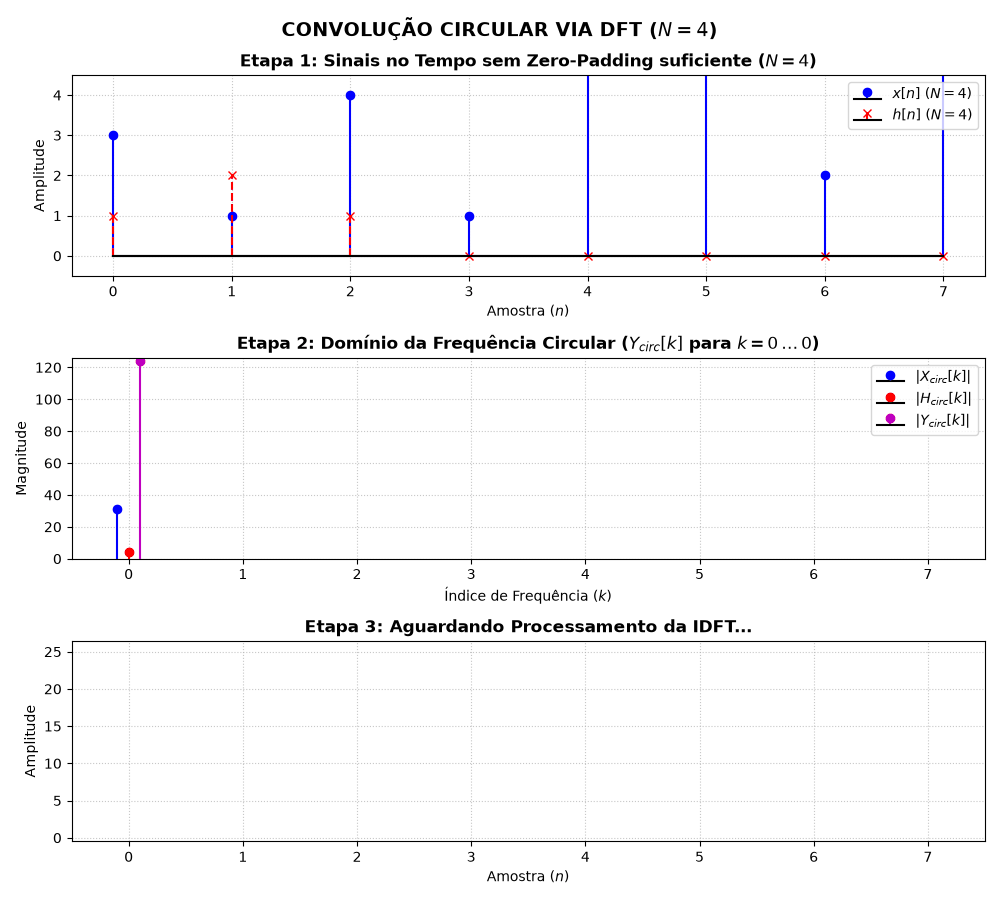

In [6]:
import matplotlib.animation as animation
from IPython.display import Image, display

from ipynb.fs.full.Algoritmo_DFT_e_IDFT import dft_imp, idft_imp

# ==============================================================================
# SINAIS DE TESTE
# ==============================================================================
x = np.array([3, 1, 4, 1, 5, 9, 2, 6], dtype=float)
h = np.array([1, 2, 1], dtype=float)

N1, N2 = len(x), len(h)
N_circ = max(N1, N2)  # N = 4 (sem espaço para expansão)

x_circ_pad = np.pad(x, (0, N_circ - N1))
h_circ_pad = np.pad(h, (0, N_circ - N2))

X_circ = dft_imp(x_circ_pad)
H_circ = dft_imp(h_circ_pad)
Y_circ = X_circ * H_circ
y_circ = idft_imp(Y_circ).real

# ==============================================================================
# ANIMAÇÃO: 3 ETAPAS DA CONVOLUÇÃO CIRCULAR
# ==============================================================================
fig2, axs2 = plt.subplots(3, 1, figsize=(10, 9))
eixo_n = np.arange(N_circ)

def draw_frame_circular(frame):
    for ax in axs2:
        ax.clear()
        ax.grid(True, ls=':', alpha=0.7)
        
    # --- Etapa 1: Tempo com Tamanho N = 4 ---
    axs2[0].stem(eixo_n, x_circ_pad, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$x[n]$ ($N=4$)')
    axs2[0].stem(eixo_n, h_circ_pad, linefmt='r--', markerfmt='rx', basefmt='k-', label=r'$h[n]$ ($N=4$)')
    axs2[0].set_title(r'Etapa 1: Sinais no Tempo sem Zero-Padding suficiente ($N = 4$)', fontweight='bold')
    axs2[0].set_xlabel(r'Amostra ($n$)')
    axs2[0].set_ylabel('Amplitude')
    axs2[0].legend(loc='upper right')
    axs2[0].set_ylim(-0.5, 4.5)
    
    # --- Etapa 2: Frequência Circular ---
    k_count = min(frame + 1, N_circ)
    axs2[1].stem(eixo_n[:k_count] - 0.1, np.abs(X_circ)[:k_count], linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$|X_{circ}[k]|$')
    axs2[1].stem(eixo_n[:k_count], np.abs(H_circ)[:k_count], linefmt='r-', markerfmt='ro', basefmt='k-', label=r'$|H_{circ}[k]|$')
    axs2[1].stem(eixo_n[:k_count] + 0.1, np.abs(Y_circ)[:k_count], linefmt='m-', markerfmt='mo', basefmt='k-', label=r'$|Y_{circ}[k]|$')
    axs2[1].set_title(r'Etapa 2: Domínio da Frequência Circular ($Y_{circ}[k]$ para $k = 0 \dots %d$)' % (k_count - 1), fontweight='bold')
    axs2[1].set_xlabel(r'Índice de Frequência ($k$)')
    axs2[1].set_ylabel('Magnitude')
    axs2[1].set_xlim(-0.5, N_circ - 0.5)
    axs2[1].set_ylim(0, max(np.abs(Y_circ)) + 2)
    axs2[1].legend(loc='upper right')
    
    # --- Etapa 3: Sinal Resultante Circular (Com Aliasing) ---
    if frame >= N_circ - 1:
        n_count = frame - (N_circ - 1) + 1
        axs2[2].stem(eixo_n[:n_count], y_circ[:n_count], linefmt='m-', markerfmt='mo', basefmt='k-', label=r'IDFT $y_{circ}[n]$ (Com Aliasing)')
        axs2[2].set_title(r'Etapa 3: Sinal Resultante Circular ($n = 0 \dots %d$)' % (n_count - 1), fontweight='bold')
    else:
        axs2[2].set_title(r'Etapa 3: Aguardando Processamento da IDFT...', fontweight='bold')
        
    axs2[2].set_xlabel(r'Amostra ($n$)')
    axs2[2].set_ylabel('Amplitude')
    axs2[2].set_xlim(-0.5, N_circ - 0.5)
    axs2[2].set_ylim(-0.5, max(y_circ) + 1.5)
    if frame >= N_circ - 1:
        axs2[2].legend(loc='upper right')
    
    fig2.suptitle(r'CONVOLUÇÃO CIRCULAR VIA DFT ($N=4$)', fontsize=14, fontweight='bold')
    plt.tight_layout()

ani_circ = animation.FuncAnimation(fig2, draw_frame_circular, frames=2*N_circ, interval=700, repeat=True)
ani_circ.save('convolucao_circular_dft_animada.gif', writer='pillow', fps=1.2)
plt.close(fig2)

display(Image(filename='convolucao_circular_dft_animada.gif'))

# Construindo uma convolução linear a partir da convolução circular

In [7]:
import numpy as np

# Importando a função de convolução circular definida anteriormente
from ipynb.fs.full.Algoritmo_DFT_e_IDFT import dft_imp, idft_imp

def convolucao_circular(x, h):
    """
    Bloco primitivo: calcula a convolução circular entre dois sinais
    no domínio da frequência via DFT/IDFT.
    """
    N = max(len(x), len(h))
    
    x_pad = np.pad(x, (0, N - len(x)))
    h_pad = np.pad(h, (0, N - len(h)))
    
    X = dft_imp(x_pad)
    H = dft_imp(h_pad)
    
    return idft_imp(X * H).real


def convolucao_linear_via_circular(x, h):
    """
    Executa a convolução linear envelopando a função de convolução circular
    através da técnica de zero-padding.
    """
    N1 = len(x)
    N2 = len(h)
    
    # 1. Comprimento exato da saída linear
    L = N1 + N2 - 1
    
    # 2. Aplicação do Zero-Padding nos vetores de entrada
    x_padded = np.pad(x, (0, L - N1))
    h_padded = np.pad(h, (0, L - N2))
    
    # 3. Chamada direta da função de convolução circular existente
    y_linear = convolucao_circular(x_padded, h_padded)
    
    return y_linear

In [9]:
# Sinais de teste
x = np.array([3, 1, 4, 1, 5, 9, 2, 6])
h = np.array([1.0, 1.0, 1.0])

# Execução da convolução linear construída via circular
y_calculado = convolucao_linear_via_circular(x, h)

# Referência nativa do NumPy
y_referencia = np.convolve(x, h)

print("Sinal x[n]:", x)
print("Filtro h[n]:", h)
print("\n--- RESULTADOS ---")
print("Linear via Convolução Circular:", np.round(y_calculado, 4))
print("Referência NumPy (np.convolve):", np.round(y_referencia, 4))

erro_max = np.max(np.abs(y_calculado - y_referencia))
print(f"\nErro Máximo Absoluto: {erro_max:.2e}")

Sinal x[n]: [3 1 4 1 5 9 2 6]
Filtro h[n]: [1. 1. 1.]

--- RESULTADOS ---
Linear via Convolução Circular: [ 3.  4.  8.  6. 10. 15. 16. 17.  8.  6.]
Referência NumPy (np.convolve): [ 3.  4.  8.  6. 10. 15. 16. 17.  8.  6.]

Erro Máximo Absoluto: 1.95e-14


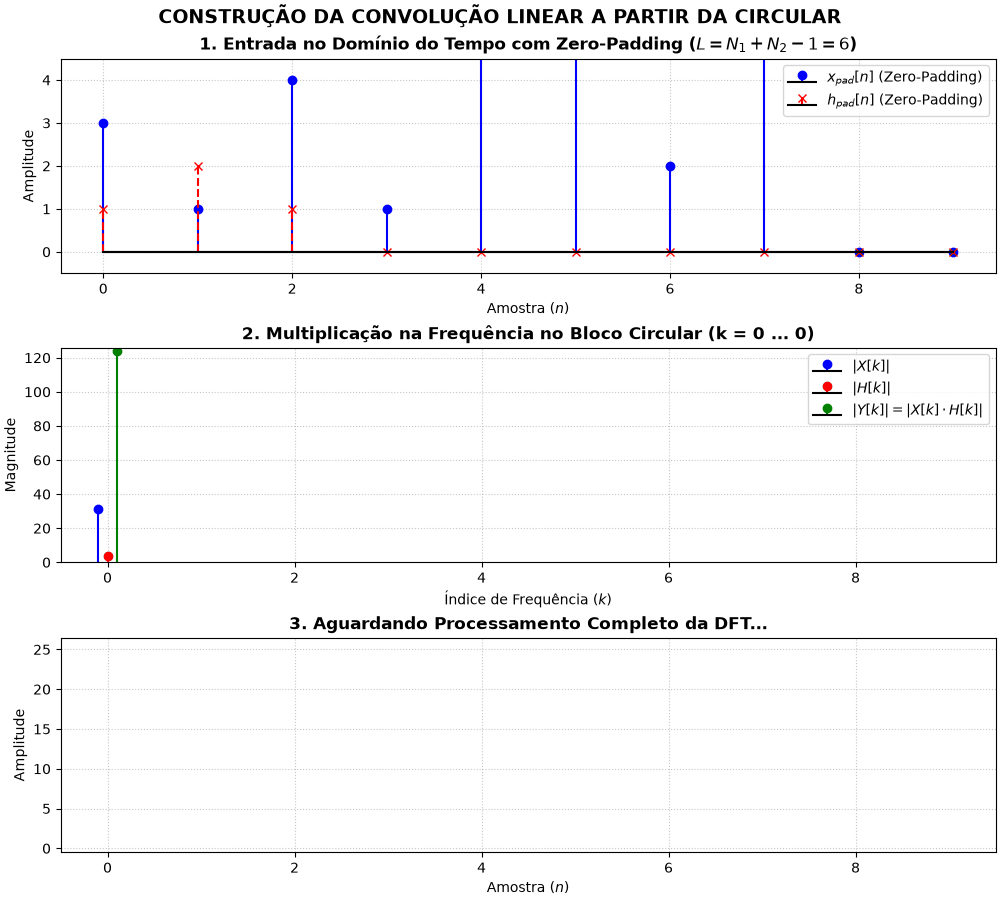

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image, display

# ==============================================================================
# 0. ALGORITMOS DE DFT E IDFT EMBUTIDOS (Evita erro de importação)
# ==============================================================================
def dft_imp(x):
    N = len(x)
    n = np.arange(N)
    k = n.reshape((N, 1))
    W = np.exp(-1j * 2 * np.pi * k * n / N)
    return np.dot(W, x)

def idft_imp(X):
    N = len(X)
    n = np.arange(N)
    k = n.reshape((N, 1))
    W_inv = np.exp(1j * 2 * np.pi * k * n / N)
    return np.dot(W_inv, X) / N

# ==============================================================================
# 1. SINAIS DE ENTRADA E PROCESSAMENTO
# ==============================================================================
x = np.array([3, 1, 4, 1, 5, 9, 2, 6])
h = np.array([1.0, 2.0, 1.0])

N1, N2 = len(x), len(h)
L = N1 + N2 - 1  # L = 6 (Zero-padding exato para convolução linear)

x_pad = np.pad(x, (0, L - N1))
h_pad = np.pad(h, (0, L - N2))

X_pad = dft_imp(x_pad)
H_pad = dft_imp(h_pad)
Y_pad = X_pad * H_pad
y_lin = idft_imp(Y_pad).real

# ==============================================================================
# 2. CONFIGURAÇÃO DA ANIMAÇÃO DO GIF 1 (Com layout="constrained")
# ==============================================================================
fig1, axs1 = plt.subplots(3, 1, figsize=(10, 9), layout="constrained")
eixo_l = np.arange(L)

def update_gif1(frame):
    for ax in axs1:
        ax.clear()
        ax.grid(True, ls=':', alpha=0.7)
        
    # --- Etapa 1: Tempo com Zero-Padding ---
    axs1[0].stem(eixo_l, x_pad, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$x_{pad}[n]$ (Zero-Padding)')
    axs1[0].stem(eixo_l, h_pad, linefmt='r--', markerfmt='rx', basefmt='k-', label=r'$h_{pad}[n]$ (Zero-Padding)')
    axs1[0].set_title(r'1. Entrada no Domínio do Tempo com Zero-Padding ($L = N_1 + N_2 - 1 = 6$)', fontweight='bold')
    axs1[0].set_xlabel(r'Amostra ($n$)')
    axs1[0].set_ylabel('Amplitude')
    axs1[0].legend(loc='upper right')
    axs1[0].set_ylim(-0.5, 4.5)
    
    # --- Etapa 2: Multiplicação na Frequência no Bloco Circular ---
    k_count = min(frame + 1, L)
    axs1[1].stem(eixo_l[:k_count] - 0.1, np.abs(X_pad)[:k_count], linefmt='b-', markerfmt='bo', basefmt='k-', label=r'$\vert{}X[k]\vert{}$')
    axs1[1].stem(eixo_l[:k_count], np.abs(H_pad)[:k_count], linefmt='r-', markerfmt='ro', basefmt='k-', label=r'$\vert{}H[k]\vert{}$')
    axs1[1].stem(eixo_l[:k_count] + 0.1, np.abs(Y_pad)[:k_count], linefmt='g-', markerfmt='go', basefmt='k-', label=r'$\vert{}Y[k]\vert{} = \vert{}X[k] \cdot H[k]\vert{}$')
    axs1[1].set_title(f'2. Multiplicação na Frequência no Bloco Circular (k = 0 ... {k_count - 1})', fontweight='bold')
    axs1[1].set_xlabel(r'Índice de Frequência ($k$)')
    axs1[1].set_ylabel('Magnitude')
    axs1[1].set_xlim(-0.5, L - 0.5)
    axs1[1].set_ylim(0, max(np.abs(Y_pad)) + 2)
    axs1[1].legend(loc='upper right')
    
    # --- Etapa 3: Reconstrução Temporal via IDFT ---
    if frame >= L - 1:
        n_count = frame - (L - 1) + 1
        axs1[2].stem(eixo_l[:n_count], y_lin[:n_count], linefmt='g-', markerfmt='go', basefmt='k-', label=r'Linear via Circular $y_{calc}[n]$')
        axs1[2].plot(eixo_l, np.convolve(x, h), 'r--x', alpha=0.4, label=r'Referência NumPy (`np.convolve`)')
        axs1[2].set_title(f'3. Reconstrução Temporal via IDFT (n = 0 ... {n_count - 1})', fontweight='bold')
        axs1[2].legend(loc='upper right')
    else:
        axs1[2].set_title('3. Aguardando Processamento Completo da DFT...', fontweight='bold')
        
    axs1[2].set_xlabel(r'Amostra ($n$)')
    axs1[2].set_ylabel('Amplitude')
    axs1[2].set_xlim(-0.5, L - 0.5)
    axs1[2].set_ylim(-0.5, max(y_lin) + 1.5)
        
    fig1.suptitle(r'CONSTRUÇÃO DA CONVOLUÇÃO LINEAR A PARTIR DA CIRCULAR', fontsize=14, fontweight='bold')

# Geração da Animação e salvamento seguro via Pillow
ani1 = animation.FuncAnimation(fig1, update_gif1, frames=2*L, interval=700, repeat=True)
ani1.save('gif1_linear_via_circular.gif', writer='pillow', fps=1.2)
plt.close(fig1)

# Exibição no Jupyter
display(Image(filename='gif1_linear_via_circular.gif'))

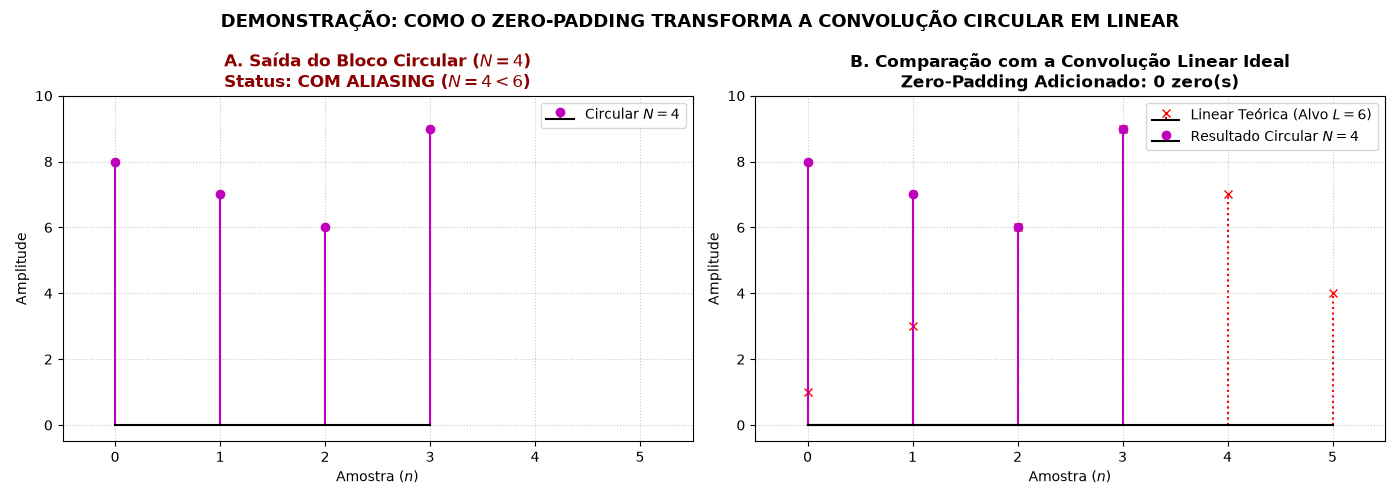

In [12]:
from ipynb.fs.full.Algoritmo_DFT_e_IDFT import dft_imp, idft_imp

# ==============================================================================
# SINAIS DE TESTE
# ==============================================================================
x = np.array([1.0, 2.0, 3.0, 4.0])
h = np.array([1.0, 1.0, 1.0])

N1, N2 = len(x), len(h)
L = N1 + N2 - 1  # L = 6 (Tamanho ideal sem aliasing)
y_lin_ref = np.convolve(x, h)

# ==============================================================================
# CONFIGURAÇÃO DA ANIMAÇÃO DE TRANSIÇÃO
# ==============================================================================
fig2, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 5))

def update_gif2(frame):
    ax_a.clear()
    ax_b.clear()
    ax_a.grid(True, ls=':', alpha=0.7)
    ax_b.grid(True, ls=':', alpha=0.7)
    
    # N oscila dinamicamente entre 4, 5 e 6
    N_current = 4 + (frame % 3)
    zeros_add = N_current - 4
    
    # Cálculo da Convolução Circular com N_current
    x_c = np.pad(x, (0, N_current - N1))
    h_c = np.pad(h, (0, N_current - N2))
    X_c = dft_imp(x_c)
    H_c = dft_imp(h_c)
    y_c = idft_imp(X_c * H_c).real
    
    eixo_c = np.arange(N_current)
    eixo_l = np.arange(L)
    
    cor = 'm' if N_current < L else 'g'
    status = f"COM ALIASING ($N={N_current} < {L}$)" if N_current < L else f"SEM ALIASING ($N={N_current} = L$)"
    cor_titulo = 'darkred' if N_current < L else 'darkgreen'
    
    # --- Painel A: Saída do Bloco Circular ---
    ax_a.stem(eixo_c, y_c, linefmt=f'{cor}-', markerfmt=f'{cor}o', basefmt='k-', label=f'Circular $N={N_current}$')
    ax_a.set_title(f'A. Saída do Bloco Circular ($N={N_current}$)\nStatus: {status}', fontweight='bold', color=cor_titulo)
    ax_a.set_xlabel(r'Amostra ($n$)')
    ax_a.set_ylabel('Amplitude')
    ax_a.set_xlim(-0.5, L - 0.5)
    ax_a.set_ylim(-0.5, 10)
    ax_a.legend(loc='upper right')
    
    # --- Painel B: Comparação com a Convolução Linear Teórica ---
    ax_b.stem(eixo_l, y_lin_ref, linefmt='r:', markerfmt='rx', basefmt='k-', label=r'Linear Teórica (Alvo $L=6$)')
    ax_b.stem(eixo_c, y_c, linefmt=f'{cor}-', markerfmt=f'{cor}o', basefmt='k-', label=f'Resultado Circular $N={N_current}$')
    ax_b.set_title(f'B. Comparação com a Convolução Linear Ideal\nZero-Padding Adicionado: {zeros_add} zero(s)', fontweight='bold')
    ax_b.set_xlabel(r'Amostra ($n$)')
    ax_b.set_ylabel('Amplitude')
    ax_b.set_xlim(-0.5, L - 0.5)
    ax_b.set_ylim(-0.5, 10)
    ax_b.legend(loc='upper right')
    
    fig2.suptitle('DEMONSTRAÇÃO: COMO O ZERO-PADDING TRANSFORMA A CONVOLUÇÃO CIRCULAR EM LINEAR', fontsize=13, fontweight='bold')
    plt.tight_layout()

# Geração da animação
ani2 = animation.FuncAnimation(fig2, update_gif2, frames=9, interval=1200, repeat=True)
ani2.save('gif2_circular_para_linear.gif', writer='pillow', fps=1)
plt.close(fig2)

# Exibição no Jupyter Notebook
display(Image(filename='gif2_circular_para_linear.gif'))